In [4]:
import sys
from pathlib import Path
import xarray as xr

# 1. Ensure Python can find the 'src' directory from the 'notebooks' folder
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

# 2. Import your spatial slicing function
from src.ingestion import slice_bay_of_bengal

# 3. Load the raw Copernicus NetCDF dataset
nc_path = project_root / "data" / "raw" / "st.nc"
ds = xr.open_dataset(nc_path)

# 4. Extract the primary ocean temperature variable
# In Copernicus physical reanalysis, ocean temperature is 'thetao'
var_name = "thetao" if "thetao" in ds else list(ds.data_vars)[0]
da_raw = ds[var_name]

# 5. Run your function to slice the Bay of Bengal region
da_sliced = slice_bay_of_bengal(da_raw)

# 6. Print inspection summaries
print("=== VERIFICATION SUMMARY ===")
print("Original Variable:", var_name)
print("Original Dimensions:", da_raw.dims)
print("Original Shape:     ", da_raw.shape)
print("-" * 30)
print("Sliced Shape:       ", da_sliced.shape)

# Detect which coordinate names were used
lat_col = next(c for c in ["latitude", "lat"] if c in da_sliced.coords)
lon_col = next(c for c in ["longitude", "lon"] if c in da_sliced.coords)

min_lat_found = float(da_sliced[lat_col].min())
max_lat_found = float(da_sliced[lat_col].max())
min_lon_found = float(da_sliced[lon_col].min())
max_lon_found = float(da_sliced[lon_col].max())

print(f"Latitude Span:       {min_lat_found:.3f}°N to {max_lat_found:.3f}°N")
print(f"Longitude Span:      {min_lon_found:.3f}°E to {max_lon_found:.3f}°E")

=== VERIFICATION SUMMARY ===
Original Variable: thetao
Original Dimensions: ('time', 'depth', 'latitude', 'longitude')
Original Shape:      (1, 1, 2041, 4320)
------------------------------
Sliced Shape:        (1, 1, 241, 180)
Latitude Span:       5.000°N to 25.000°N
Longitude Span:      80.000°E to 94.917°E


In [5]:
from pathlib import Path
import xarray as xr

# Step up to the project root from the notebooks directory
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
nc_path = project_root / "data" / "raw" / "st.nc"

ds = xr.open_dataset(nc_path)
print("Variables in this file:", list(ds.data_vars.keys()))

Variables in this file: ['thetao']


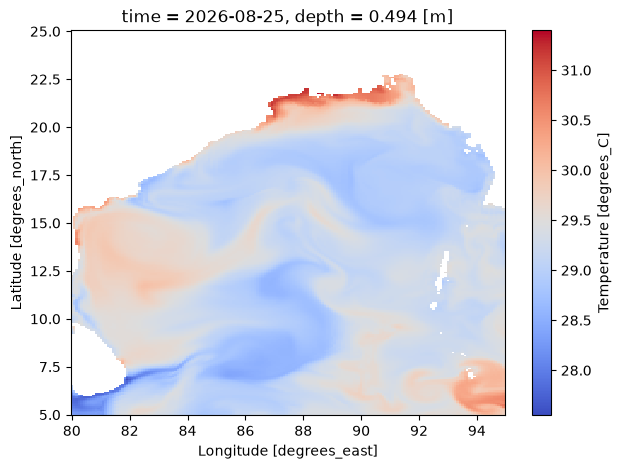

In [6]:
# Select the first time step and top depth layer if multi-dimensional
sample_2d = da_sliced.isel(time=0) if "time" in da_sliced.dims else da_sliced
if "depth" in sample_2d.dims:
    sample_2d = sample_2d.isel(depth=0)

# Plot the cropped ocean grid
sample_2d.plot(cmap="coolwarm", figsize=(7, 5))